In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
!pip install -U scikit-learn

In [5]:
#Read Data
df = pd.read_csv('PHL PISA.csv',low_memory=False)
print(df.columns)
print(df.shape)

Index(['CNT', 'CNTRYID', 'CNTSCHID', 'CNTSTUID', 'CYC', 'NatCen', 'STRATUM',
       'SUBNATIO', 'REGION', 'OECD',
       ...
       'PV4MPRE', 'PV5MPRE', 'PV6MPRE', 'PV7MPRE', 'PV8MPRE', 'PV9MPRE',
       'PV10MPRE', 'SENWT', 'VER_DAT', 'filter_$'],
      dtype='object', length=1279)
(7193, 1279)


In [7]:
#Data Preparation
from sklearn.impute import KNNImputer

df=df[['CNTSTUID','ST004D01T','BULLIED','BELONG','TEACHSUP','ICTRES','ANXMAT','ST016Q01NA','ST347Q01JA','RELATST','PROBSELF','FEELSAFE','FAMSUP','FEELLAH','DISCLIM','TARDYSD','SKIPPING','MISSSC','CREATOR','CREATOPN','ICTWKEND','ICTWKDY','IMAGINE','CREATOP','CREATEFF','CREATSCH','STRESAGR','PERSEVAGR','EMOCOAGR','CURIOAGR','COOPAGR','ASSERAGR','HOMEPOS','GROSAGR','LANGN','IMMIG','SISCO','BSMJ','EXPECEDU','HISEI','HISCED','PV1MATH']]
df=pd.DataFrame(df)

df.loc[df['PV1MATH'] >= 358, 'PV1MATH_CONVERTED'] = 0 #High Performing Students
df.loc[df['PV1MATH'] < 358, 'PV1MATH_CONVERTED'] = 1 #Low Performing Students

df = df.apply(pd.to_numeric, errors='coerce')
print(df.head())

#X=pd.DataFrame(df[['ST004D01T','BULLIED','BELONG','TEACHSUP','ICTRES','ANXMAT','ST016Q01NA','ST347Q01JA','RELATST','PROBSELF','FEELSAFE','FAMSUP','FEELLAH','DISCLIM','TARDYSD','SKIPPING','MISSSC','CREATOR','CREATOPN','ICTWKEND','ICTWKDY','IMAGINE','CREATOP','CREATEFF','CREATSCH','STRESAGR','PERSEVAGR','EMOCOAGR','CURIOAGR','COOPAGR','ASSERAGR','HOMEPOS','GROSAGR','LANGN','IMMIG','SISCO','BSMJ','EXPECEDU','HISEI','HISCED']])

#Replace Valid Skip, No response,invalid, and Not Applicable values with NaN
df=df.replace([95,97,98,99,''],np.nan)
df['HISEI'] = df['HISEI'].replace({995: np.nan, 997: np.nan,998: np.nan,999: np.nan})
df['MISSSC'] = df['MISSSC'].replace(9,np.nan)
df['SISCO'] = df['SISCO'].replace({5: np.nan, 7: np.nan,8: np.nan,9: np.nan})
df['IMMIG'] = df['IMMIG'].replace({5: np.nan, 7: np.nan,8: np.nan,9: np.nan})
df['TARDYSD'] = df['TARDYSD'].replace({5: np.nan, 7: np.nan,8: np.nan,9: np.nan})
df['SKIPPING'] = df['SKIPPING'].replace({5: np.nan, 7: np.nan,8: np.nan,9: np.nan})
df['ST004D01T'] = df['ST004D01T'].replace({5: np.nan, 7: np.nan,8: np.nan,9: np.nan})

print("count of NaN ST004D01T",df['ST004D01T'].isna().sum())
df = df.apply(pd.to_numeric, errors='coerce')

#Remove columns with 100% NaN
df=df.dropna(axis=1, how='all')
print('df',df)

#Remove rows with more than 50% NaN
threshold = int(df.shape[1] * 0.5)  # 50% of the number of columns
df=df.dropna(thresh=threshold) # Drop rows with more than 50% NaN values
print(df.shape)

#Remove rows if PV1MATH_CONVERTED is blank/missing
df=df.dropna(subset=['PV1MATH_CONVERTED'])

#Separate df into X and y
X=df.drop(['PV1MATH','CNTSTUID','PV1MATH_CONVERTED'],axis=1)
y = df['PV1MATH_CONVERTED']

# Impute Missing values using KNN
imputer = KNNImputer(n_neighbors=3, weights='uniform')
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

X = X.apply(pd.to_numeric, errors='coerce')
print(X)



   CNTSTUID  ST004D01T  BULLIED  BELONG  TEACHSUP  ICTRES  ANXMAT  ST016Q01NA  \
0  60800001          1  -1.2280 -0.0328    0.8211 -0.1534      97         6.0   
1  60800002          1   0.5402 -0.3261    0.8211 -3.4555      97         6.0   
2  60800003          2   1.8190  0.2694    0.8211 -0.2204      97         8.0   
3  60800004          1   1.2320 -1.1963   -0.3322 -2.0639      97        10.0   
4  60800005          2  -0.1325 -0.2482    1.5558 -1.7624      97         8.0   

   ST347Q01JA  RELATST  ...  GROSAGR  LANGN  IMMIG  SISCO   BSMJ  EXPECEDU  \
0         6.0       97  ...   0.2216    910      1      1  79.49       9.0   
1         3.0       97  ...  -0.3061    108      1      1  60.92       8.0   
2         2.0       97  ...   0.5849    108      1      1  81.40       9.0   
3         NaN       97  ...  -0.1600    108      9      9  99.00      99.0   
4        99.0       97  ...   0.7798    914      1      9  99.00      99.0   

   HISEI  HISCED  PV1MATH  PV1MATH_CONVERTED

In [94]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 7099 entries, 0 to 7192
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CNTSTUID           7099 non-null   int64  
 1   ST004D01T          7099 non-null   int64  
 2   BULLIED            6972 non-null   float64
 3   BELONG             6953 non-null   float64
 4   TEACHSUP           6753 non-null   float64
 5   ICTRES             7081 non-null   float64
 6   ST016Q01NA         6869 non-null   float64
 7   ST347Q01JA         5566 non-null   float64
 8   PROBSELF           4301 non-null   float64
 9   FEELSAFE           7031 non-null   float64
 10  FAMSUP             6038 non-null   float64
 11  FEELLAH            3122 non-null   float64
 12  DISCLIM            6778 non-null   float64
 13  TARDYSD            6864 non-null   float64
 14  SKIPPING           6976 non-null   float64
 15  MISSSC             7012 non-null   float64
 16  CREATOP            6227 non-n

In [9]:
!pip install imbalanced-learn

In [131]:
#Remove Bias in training data set
from imblearn.under_sampling import TomekLinks
from imblearn.over_sampling import SMOTE

X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=0)

#print(len(X_train))
#print(len(y_train))
print((y_test==0).sum())
print((y_test==1).sum())
print((y_train==0).sum())
print((y_train==1).sum())
smote = SMOTE(sampling_strategy=0.887,random_state=10)
tomek = TomekLinks()

# Apply SMOTE to oversample the minority class in the training data
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Apply Tomek Links to remove borderline instances
X_train_resampled, y_train_resampled = tomek.fit_resample(X_train_resampled, y_train_resampled)


#print(len(X_train_resampled))
#print(len(y_train_resampled))

print((y_train_resampled==0).sum())
print((y_train_resampled==1).sum())

625
795
2490
3189
2828
2825


In [33]:
#Distribution bar chart per level

import pandas as pd
import numpy as np

A=df
# Define the conditions for categorizing 'PV1MATH'
conditions = [
    (A['PV1MATH'] <= 358),  # Condition for Level 1
    (A['PV1MATH'] > 358) & (df['PV1MATH'] <= 420),  # Condition for Level 2
    (A['PV1MATH'] > 420) & (df['PV1MATH'] <= 482), # Condition for Level 3
    (A['PV1MATH'] > 482) & (df['PV1MATH'] <= 545), # Condition for Level 4
    (A['PV1MATH'] > 545) & (df['PV1MATH'] <= 607), # Condition for Level 5
    (A['PV1MATH'] > 607) & (df['PV1MATH'] <= 669), # Condition for Level 6
]

# Define the corresponding levels
levels = ['Level 1', 'Level 2', 'Level 3','Level 4','Level 5','Level 6']

# Use np.select() to assign the level based on the conditions
A['PV1MATH_LEVEL'] = np.select(conditions, levels, default='Unknown')

# Print the result
print(A[['PV1MATH', 'PV1MATH_LEVEL']])

      PV1MATH PV1MATH_LEVEL
0     475.335       Level 3
1     307.599       Level 1
2     473.640       Level 3
3     282.073       Level 1
4     470.181       Level 3
...       ...           ...
7188  355.593       Level 1
7189  267.847       Level 1
7190  277.356       Level 1
7191  369.106       Level 2
7192  344.309       Level 1

[7099 rows x 2 columns]


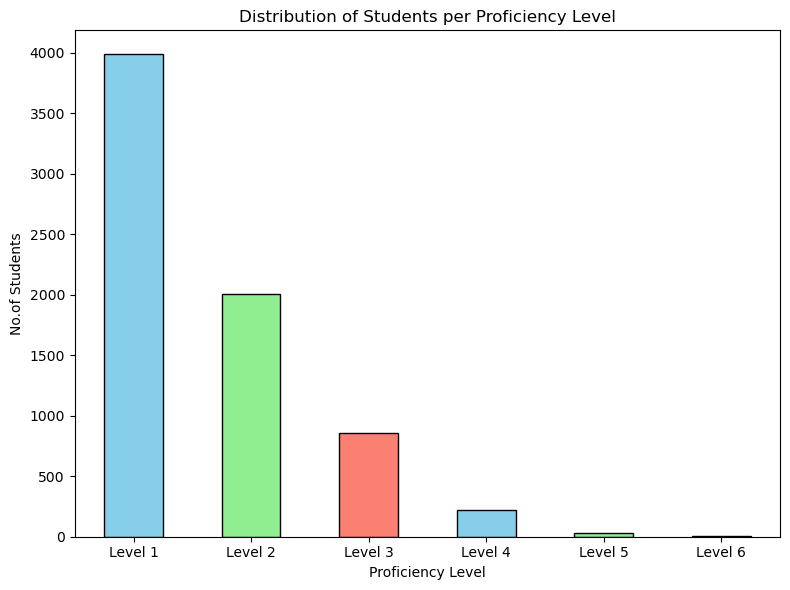

In [41]:
#Plot bar chart
level_counts = A['PV1MATH_LEVEL'].value_counts()

# Plot the bar chart
plt.figure(figsize=(8, 6))
level_counts.plot(kind='bar', color=['skyblue', 'lightgreen', 'salmon'], edgecolor='black')

# Add labels and title
plt.title('Distribution of Students per Proficiency Level')
plt.xlabel('Proficiency Level')
plt.ylabel('No.of Students')
plt.xticks(rotation=0)  # To keep x-axis labels horizontal
plt.tight_layout()
plt.savefig('barchart.jpg')
# Show the plot
plt.show()

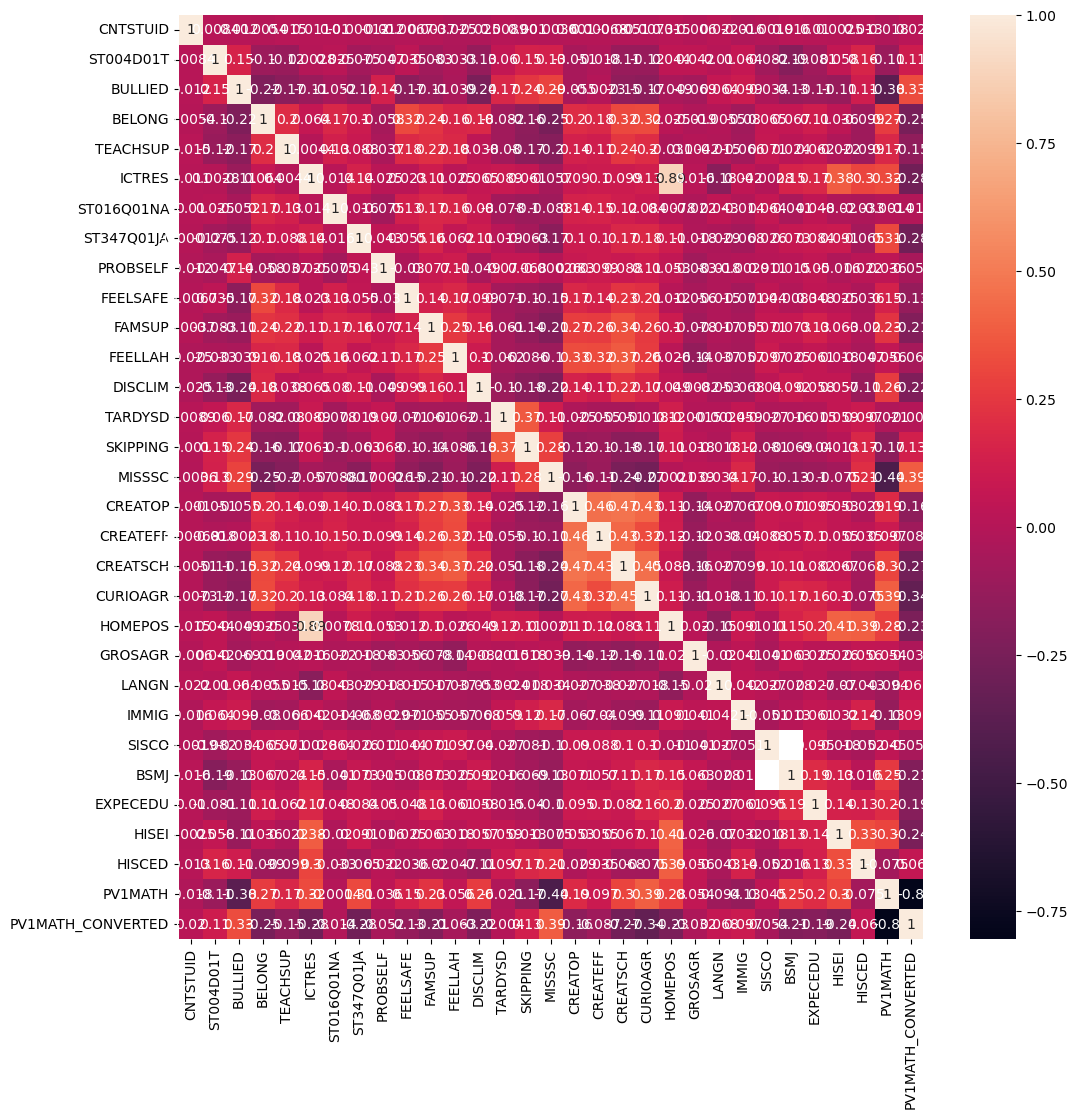

In [139]:
#Get the correlation among the data
import seaborn as sns
plt.rcParams['figure.figsize'] = 12, 12
sns.heatmap(df.corr(), annot=True)
plt.savefig('Correlation.jpg')

In [111]:
#RandomForestClassifier
#Model Training

#from sklearn.ensemble import RandomForestClassifier

#X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=0)
#X_train=X_train_resampled
#y_train=y_train_resampled
#forest=RandomForestClassifier(n_estimators=1000,random_state=2)
#forest.fit(X_train,y_train)

#print("Accuracy on training set: {:.3f}".format(forest.score(X_train,y_train)))

#print("Accuracy on test set: {:.3f}".format(forest.score(X_test,y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.775


In [113]:
#Model Evaluation using Cross-Validation
#from sklearn.model_selection import cross_val_score

#model_RFC=RandomForestClassifier(n_estimators=1000,random_state=2)
#score_RFC=cross_val_score(model_RFC,X,y)
#print("Cross-Validation Scores: {}".format(score_RFC))

Cross-Validation Scores: [0.79647887 0.77112676 0.76971831 0.79507042 0.77871741]


In [127]:
#RandomizedSeacrhCV RF
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

X_train=X_train_resampled
y_train=y_train_resampled

param_grid={'n_estimators':[200,500,1000],
           'max_depth':[20,40,60,80,100],
           'min_samples_split':[2,5,10],
           'min_samples_leaf':[1,2,4],
           'bootstrap':[True,False]}

random_search=RandomizedSearchCV(RandomForestClassifier(random_state=0),param_grid,n_iter=10,cv=3,scoring='accuracy',random_state=0,n_jobs=-1,verbose=2)
random_search.fit(X_train,y_train)

best_model_RF = random_search.best_estimator_
print(best_model_RF)
print("Best Parameters:", random_search.best_params_)
print("Test set score:{:.2f}".format(random_search.score(X_test,y_test)))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
RandomForestClassifier(bootstrap=False, max_depth=20, n_estimators=200,
                       random_state=0)
Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20, 'bootstrap': False}
Test set score:0.75


Confusion Matrix:
 [[487 138]
 [182 613]]


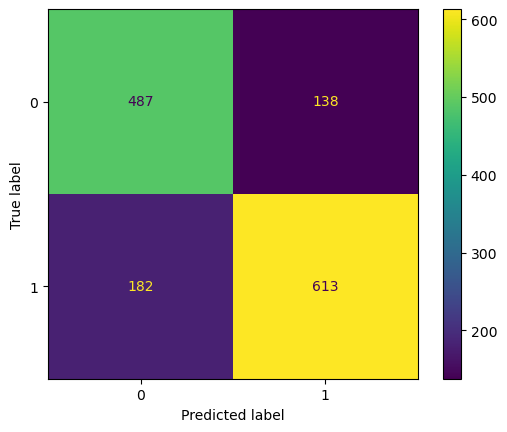

In [49]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

y_pred_RF = random_search.predict(X_test)
cm = confusion_matrix(y_test, y_pred_RF)
print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.viridis)
plt.show()

In [51]:
#Classification Report RF
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_RF,target_names=["0","1"],digits=3))


              precision    recall  f1-score   support

           0      0.728     0.779     0.753       625
           1      0.816     0.771     0.793       795

    accuracy                          0.775      1420
   macro avg      0.772     0.775     0.773      1420
weighted avg      0.777     0.775     0.775      1420



In [55]:
#ROC-AUC RF

from sklearn.metrics import roc_auc_score

y_proba = best_model_RF.predict_proba(X_test)[:, 1]
rf_auc=roc_auc_score(y_test,y_proba)

plt.plot(fpr,tpr)
plt.xlabel("FPR")
plt.ylabel("TPR")

print("AUC:{:.3f}".format(rf_auc))

NameError: name 'fpr' is not defined

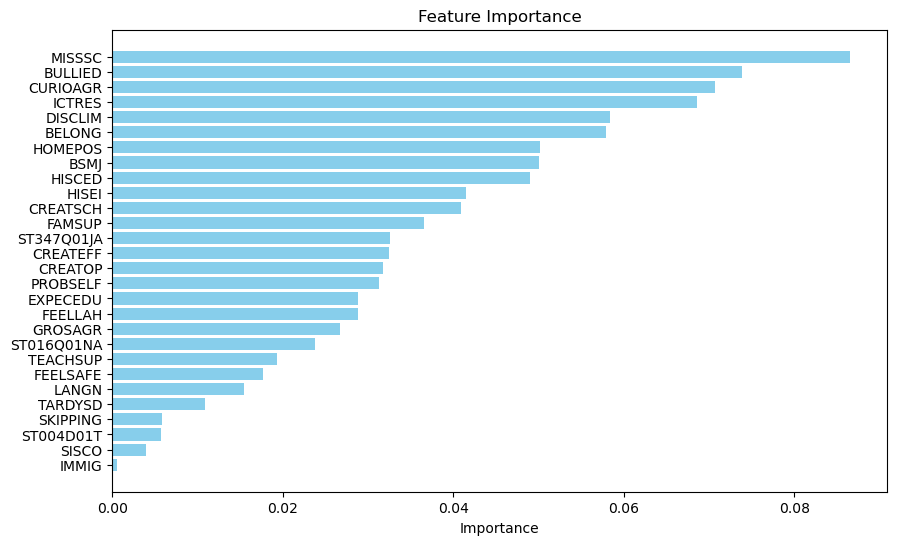

In [59]:
importances = best_model_RF.feature_importances_

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
})

# Sort the DataFrame
feature_importance_df = feature_importance_df.sort_values(by='Importance')

# Plotting
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
plt.xlabel('Importance')
plt.title('Feature Importance')
plt.show()

In [139]:
#Install SHAP
!pip install shap

In [61]:
#Logistic Regression

from sklearn.preprocessing import StandardScaler
#from sklearn.linear_model import LogisticRegression

scaler=StandardScaler()

X_scaled=pd.DataFrame(scaler.fit_transform(X),columns=X.columns)
X_scaled_cleaned = X_scaled.dropna(axis=1, how='all')
X_scaled=X_scaled_cleaned

# Fill NaN values with the mean of each column
#for column in X_scaled.columns:
 #   if X_scaled[column].dtype in [np.float64, np.int64]:  # Ensure column is numeric
  #      X_scaled[column].fillna(X_scaled[column].mean(), inplace=True)

X_scaled = X_scaled.apply(pd.to_numeric, errors='coerce')

X_train,X_test,y_train,y_test=train_test_split(X_scaled,y,test_size=0.3,random_state=20)
#log_reg=LogisticRegression()
#log_reg.fit(X_train,y_train)

#print("Training Set Score: {:.2f}".format(log_reg.score(X_train,y_train)))
#print("Test Set Score: {:.2f}".format(log_reg.score(X_test,y_test)))

In [65]:
#RandomizedSearchCV Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

param_distributions = {
    'C': loguniform(1e-4, 1e4),  # Inverse of regularization strength
    'penalty': ['l2', 'none'],   # Regularization types (note 'l1' only works with certain solvers)
    'solver': ['lbfgs', 'saga']  # Solvers that work with both penalties and multiclass
}

log_reg_randomized = LogisticRegression(max_iter=1000)

# Initialize RandomizedSearchCV
random_search_logreg = RandomizedSearchCV(
    estimator=log_reg_randomized,
    param_distributions=param_distributions,
    n_iter=10,         # Number of random combinations to try
    cv=5,              # 5-fold cross-validation
    random_state=42,   # Seed for reproducibility
    n_jobs=-1          # Use all available processors
)

# Fit RandomizedSearchCV to find the best parameters
random_search_logreg.fit(X_scaled, y)

best_model_LR = random_search_logreg.best_estimator_

# Output the best parameters and score
print("Best Parameters:", random_search_logreg.best_params_)
print("Best Cross-Validation Score:", random_search_logreg.best_score_)

Best Parameters: {'C': 0.002848391870910803, 'penalty': 'l2', 'solver': 'lbfgs'}
Best Cross-Validation Score: 0.7691228697059028


D:\anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
25 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
16 fits failed with the following error:
Traceback (most recent call last):
  File "D:\anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "D:\anaconda\Lib\site-packages\sklearn\base.py", line 1466, in wrapper
    estimator._validate_params()
  File "D:\anaconda\Lib\site-packages\sklearn\base.py", line 666, in _validate_params
    validate_parameter_constraints(
  File "D:\anaconda\Lib\site-packages\sklearn\utils\_param_validation.py", line 95, in validate_paramet

Confusion Matrix:
 [[660 253]
 [235 982]]


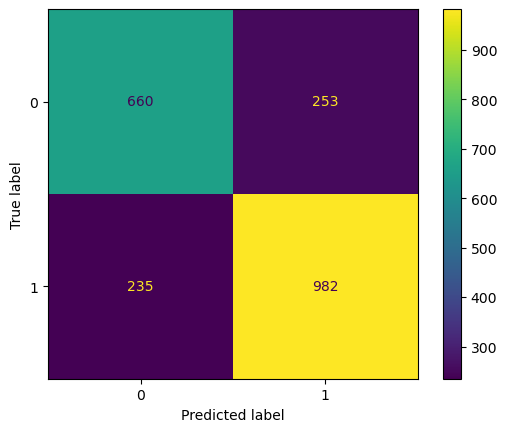

In [69]:
#Confusion Matrix LogReg
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

y_pred_logreg = best_model_LR.predict(X_test)
cm = confusion_matrix(y_test, y_pred_logreg)
print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.viridis)
plt.show()

In [71]:
#Classification Report Logreg
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_logreg,target_names=["0","1"],digits=3))

              precision    recall  f1-score   support

           0      0.737     0.723     0.730       913
           1      0.795     0.807     0.801      1217

    accuracy                          0.771      2130
   macro avg      0.766     0.765     0.766      2130
weighted avg      0.770     0.771     0.771      2130



In [75]:
#ROC-AUC Logreg

from sklearn.metrics import roc_auc_score

#log_reg=LogisticRegression()
#log_reg.fit(X_train,y_train)

y_proba = best_model_LR.predict_proba(X_test)[:, 1]
rf_auc=roc_auc_score(y_test,y_proba)

plt.plot(fpr,tpr)
plt.xlabel("FPR")
plt.ylabel("TPR")

print("AUC:{:.3f}".format(rf_auc))

NameError: name 'fpr' is not defined

Feature Importance in the Best Logistic Regression Model:
       Feature  Importance
14      MISSSC    0.474403
18    CURIOAGR   -0.332055
1      BULLIED    0.323215
6   ST347Q01JA   -0.268713
4       ICTRES   -0.252606
26       HISEI   -0.249840
17    CREATSCH   -0.187078
19     HOMEPOS   -0.167261
2       BELONG   -0.158686
11     DISCLIM   -0.151456
27      HISCED    0.138252
24        BSMJ   -0.134098
25    EXPECEDU   -0.124974
16    CREATEFF    0.114898
22       IMMIG    0.114368
20     GROSAGR   -0.107686
5   ST016Q01NA    0.097815
12     TARDYSD   -0.095254
9       FAMSUP   -0.088399
7     PROBSELF   -0.066359
3     TEACHSUP   -0.059965
23       SISCO   -0.039660
8     FEELSAFE   -0.024919
10     FEELLAH    0.022398
21       LANGN    0.019527
0    ST004D01T    0.013590
15     CREATOP   -0.011725
13    SKIPPING    0.009831


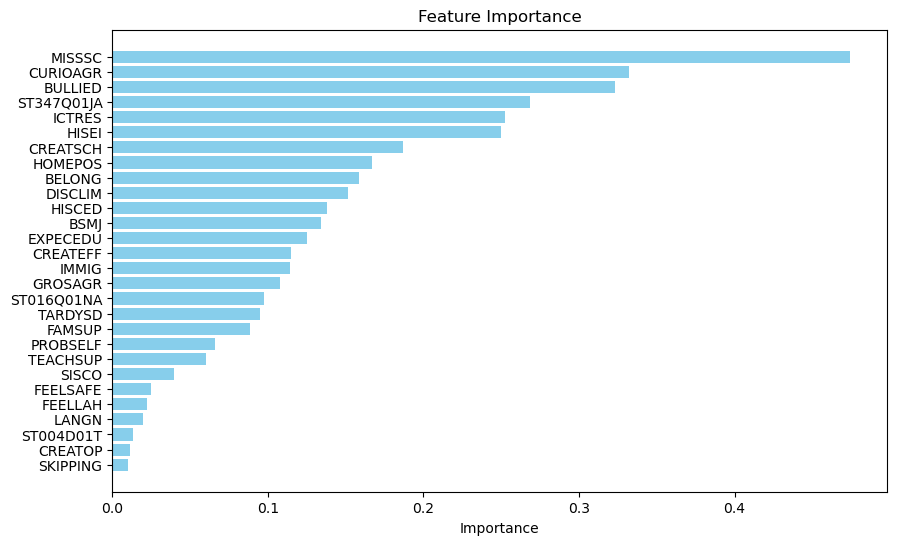

In [79]:
#Feature Importance
feature_importance = pd.DataFrame({
    'Feature': X_scaled.columns,
    'Importance': best_model_LR.coef_[0]
})

# Sort features by absolute importance
feature_importance['Absolute Importance'] = feature_importance['Importance'].abs()
feature_importance = feature_importance.sort_values(by='Absolute Importance', ascending=False)

print("Feature Importance in the Best Logistic Regression Model:")
print(feature_importance[['Feature', 'Importance']])

feature_importance= feature_importance.sort_values(by='Absolute Importance')

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Absolute Importance'], color='skyblue')
plt.xlabel('Importance')
plt.title('Feature Importance')
plt.show()

In [123]:
#Gradient Boosting Classifier

#from sklearn.ensemble import GradientBoostingClassifier

#X_transformed_gbrt=X
#print(X_transformed_gbrt.head())
# Fill NaN values with the mean of each column
#for column in X_transformed_gbrt.columns:
    #if X_transformed_gbrt[column].dtype in [np.float64, np.int64]:  # Ensure column is numeric
        #X_transformed_gbrt[column].fillna(X_transformed_gbrt[column].mean(), inplace=True)
      #  X_transformed_gbrt[column] = X_transformed_gbrt[column].fillna(X_transformed_gbrt[column].mean())

#X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=20)
#X_train=X_train_resampled
#y_train=y_train_resampled

#gbrt=GradientBoostingClassifier(random_state=0,max_depth=1)
#gbrt.fit(X_train,y_train)

#print("Accuracy on training set: {:.2f}".format(gbrt.score(X_train,y_train)))
#print("Accuracy on test set: {:.2f}".format(gbrt.score(X_test,y_test)))

Accuracy on training set: 0.80
Accuracy on test set: 0.78


In [149]:
#Classification Report gboost
#from sklearn.metrics import classification_report
#y_pred_GB = gbrt.predict(X_test)
#print(classification_report(y_test,y_pred_GB,target_names=["0","1"]))

              precision    recall  f1-score   support

           0       0.72      0.82      0.76       625
           1       0.84      0.75      0.79       795

    accuracy                           0.78      1420
   macro avg       0.78      0.78      0.78      1420
weighted avg       0.79      0.78      0.78      1420



In [200]:
#Install xgboost
!pip install xgboost

In [125]:
#XGBoost
#import xgboost as xgb
#from sklearn.metrics import accuracy_score

#X_train=X_train_resampled
#y_train=y_train_resampled

#model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss')
#model.fit(X_train, y_train)

# Predict the labels for the test set
#y_pred_xgb = model.predict(X_test)

# Evaluate the model using accuracy score
#accuracy = accuracy_score(y_test, y_pred_xgb)
#print(f"Accuracy: {accuracy}")

Accuracy: 0.7690140845070422


In [103]:
#xgboost RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score
import xgboost as xgb
# Initialize the XGBoost Classifier
xgb_model = xgb.XGBClassifier(random_state=0)

X_train=X_train_resampled
y_train=y_train_resampled

# Define the parameter grid for RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 200, 300, 400, 500,1000],
    'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
    'max_depth': [3, 4, 5, 6, 7,20,40,50],
    'min_child_weight': [1, 2, 3, 4, 5],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0]
}

# Initialize RandomizedSearchCV
random_search_xgb = RandomizedSearchCV(xgb_model, param_distributions=param_dist, 
                                   n_iter=10, cv=5, verbose=2, n_jobs=-1, random_state=42)

# Fit the model to the data
random_search_xgb.fit(X_train, y_train)

# Get the best model
best_model_xgb = random_search_xgb.best_estimator_

# Make predictions on the test set
y_pred_xgb = best_model_xgb.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred_xgb)
print(f"Accuracy of the best model: {accuracy:.4f}")

# Print the best hyperparameters
print("Best Hyperparameters found by RandomizedSearchCV:")
print(random_search_xgb.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Accuracy of the best model: 0.7793
Best Hyperparameters found by RandomizedSearchCV:
{'subsample': 0.6, 'n_estimators': 500, 'min_child_weight': 4, 'max_depth': 20, 'learning_rate': 0.01, 'colsample_bytree': 0.6}


Confusion Matrix:
 [[ 647  266]
 [ 204 1013]]


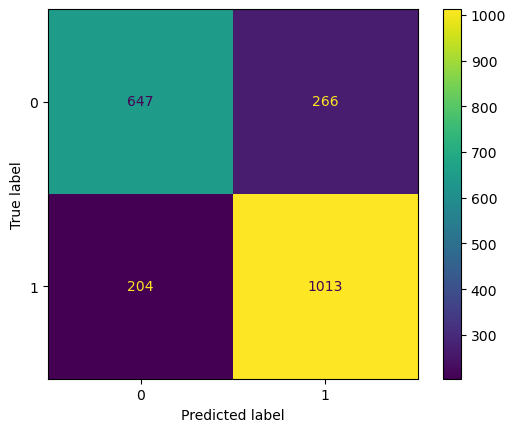

In [105]:
#Confusion Matrix xgboost
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_xgb)
print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.viridis)
plt.savefig('CM_XGB.jpg') 
plt.show()

In [107]:
#Classification Report xgboost
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred_xgb,target_names=["0","1"],digits=3))

              precision    recall  f1-score   support

           0      0.760     0.709     0.734       913
           1      0.792     0.832     0.812      1217

    accuracy                          0.779      2130
   macro avg      0.776     0.771     0.773      2130
weighted avg      0.778     0.779     0.778      2130



In [ ]:
#Gridsearch xgboost

#import xgboost as xgb
#from sklearn.model_selection import GridSearchCV
#from sklearn.datasets import load_breast_cancer
#from sklearn.model_selection import train_test_split
#from sklearn.metrics import accuracy_score


# Split into training and testing sets
#X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=20)

#X_train=X_train_resampled
#y_train=y_train_resampled

# Create the base model
#xgb_model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss')

# Define hyperparameter grid
#param_grid = {
 #   'learning_rate': [0.01, 0.1, 0.2],
  #  'n_estimators': [200,500,1000],
   # 'max_depth': [5,10,20],
    #'min_child_weight': [1, 2, 3],
   # 'subsample': [0.8, 0.9, 1.0],
   # 'colsample_bytree': [0.8, 0.9, 1.0]
#}

# Set up GridSearchCV
#grid_search = GridSearchCV(estimator=xgb_model,
 #                          param_grid=param_grid,
#                           scoring='accuracy',
#                           cv=5,
#                           verbose=1,
#                           n_jobs=-1)

# Fit grid search
#grid_search.fit(X_train, y_train)

# Best parameters and score
#best_params = grid_search.best_params_
#print("Best Parameters:", best_params)

#best_score = grid_search.best_score_
#print("Best Cross-Validation Score:", best_score)

# Get the best model and evaluate on test set
#best_model = grid_search.best_estimator_
#y_pred_XGB = best_model.predict(X_test)
#accuracy = accuracy_score(y_test, y_pred_XGB)
#print("Test Accuracy:", accuracy)


Fitting 5 folds for each of 729 candidates, totalling 3645 fits


(2130, 28)
2130
(28,)


C:\Users\user\AppData\Local\Temp\ipykernel_9100\2699712515.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=mean_shap_values.index, x=np.abs(sorted_values.values), palette=colors)


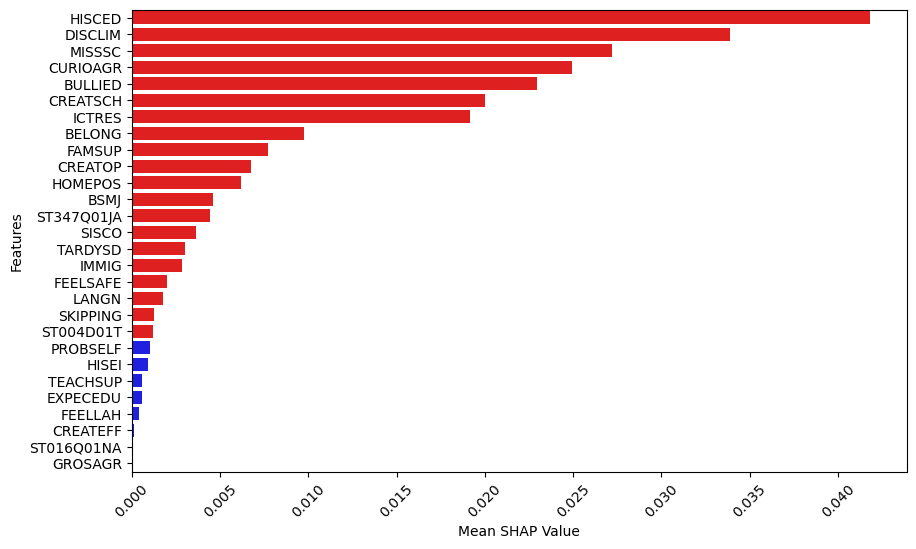

[ 3.45280487e-03  1.21123627e-01  1.94089472e-01 -1.71617270e-02
  4.88171637e-01  3.14356357e-01  3.99516493e-01 -2.64378004e-02
  1.65585186e-02  6.89194798e-02 -5.24696633e-02  3.23666781e-01
  4.29289378e-02  5.43006812e-04  7.49341905e-01  4.32010442e-02
 -1.77795179e-02  1.92265108e-01  1.14927895e-01  6.37965649e-02
  1.94511846e-01  7.40958452e-02 -4.66215832e-04 -2.48826831e-03
  6.46038353e-02 -2.95710866e-03 -1.52384415e-01 -2.09714264e-01]


In [57]:
#SHAP xgboost

import shap
import seaborn as sns
import numpy as np

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=20)

best_model_xgb=best_model

explainer = shap.TreeExplainer(best_model_xgb)
shap_values = explainer.shap_values(X_test)
print(shap_values.shape)
print(len(shap_values))

#Compute the mean SHAP values for each feature

shap_df = pd.DataFrame(shap_values, columns=X.columns)
mean_shap_values = shap_df.mean().sort_values(ascending=False)
print(mean_shap_values.shape)
#Color features based on their relationship to the class
# - Red if mean SHAP value is positive (direct relationship)
# - Blue if mean SHAP value is negative (inverse relationship)
colors = ['red' if mean_shap_values[feature] > 0 else 'blue' for feature in mean_shap_values.index]

sorted_values = mean_shap_values.iloc[np.abs(mean_shap_values.values).argsort()[::-1]]
# Step 7: Plot the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(y=mean_shap_values.index, x=np.abs(sorted_values.values), palette=colors)

plt.ylabel("Features")
plt.xlabel("Mean SHAP Value")
plt.xticks(rotation=45)
plt.show()
print(shap_values[1])

In [109]:
import shap
explainer = shap.TreeExplainer(best_model_xgb)
shap_values_bin = explainer(X_test)
print(shap_values_bin.shape)

shap_values_bin_means=shap_values_bin.mean(axis=0)
print(shap_values_bin_means.shape)
#shap_values_class_1 = shap_values_bin[1].values
#print(shap_values_class_1.shape)

(2130, 28)
(28,)


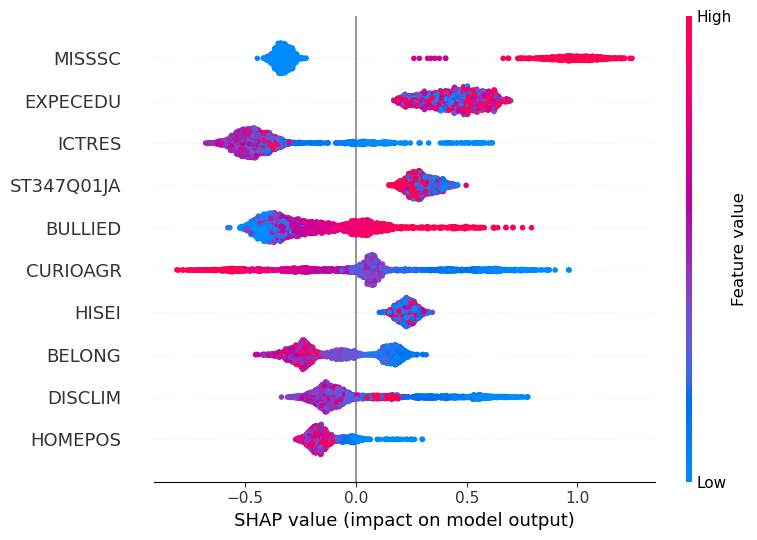

In [111]:
shap.summary_plot(shap_values_bin, X_test,max_display=10)

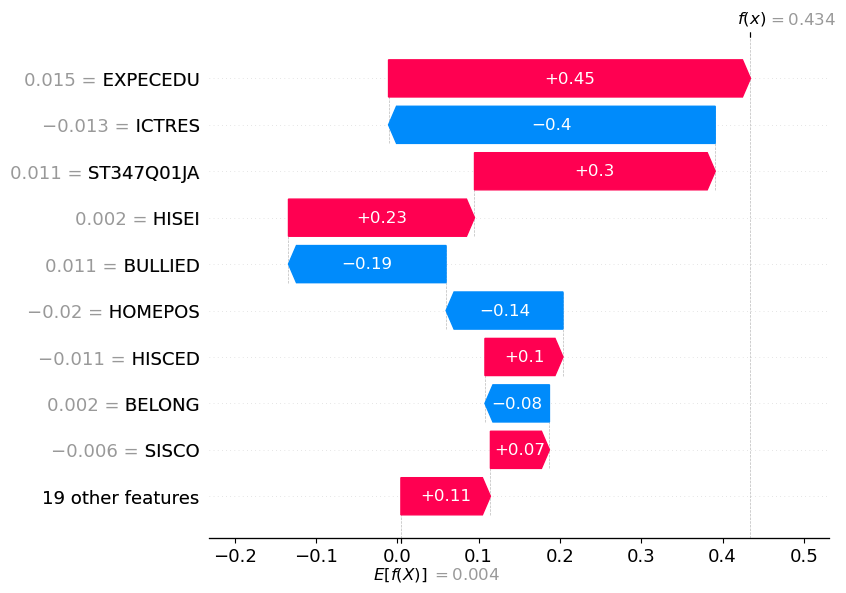

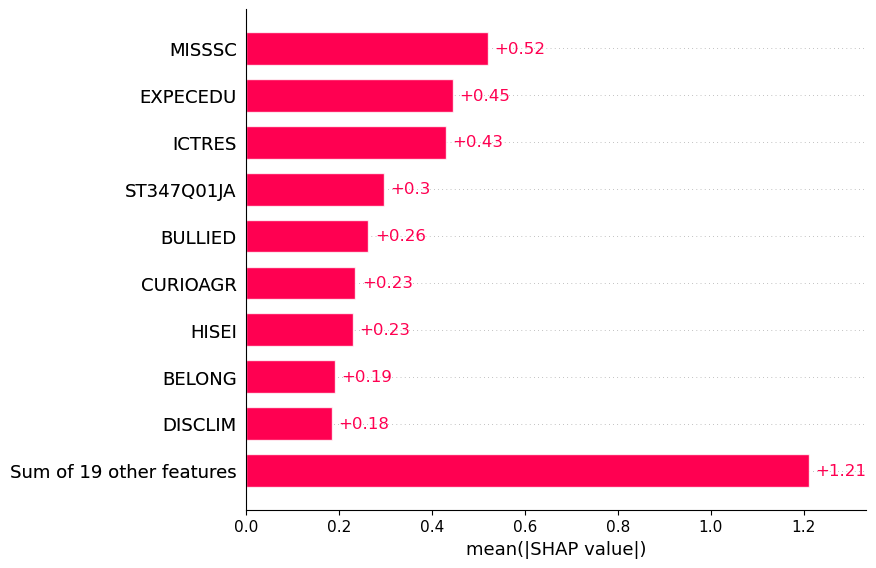

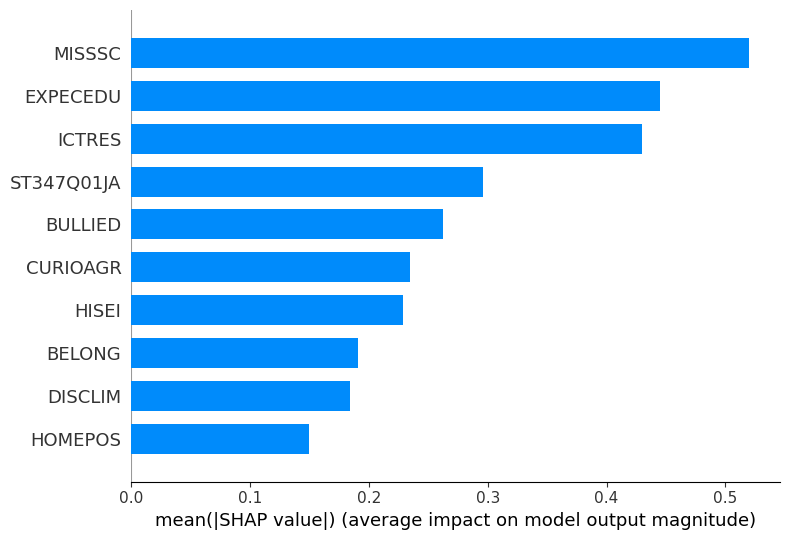

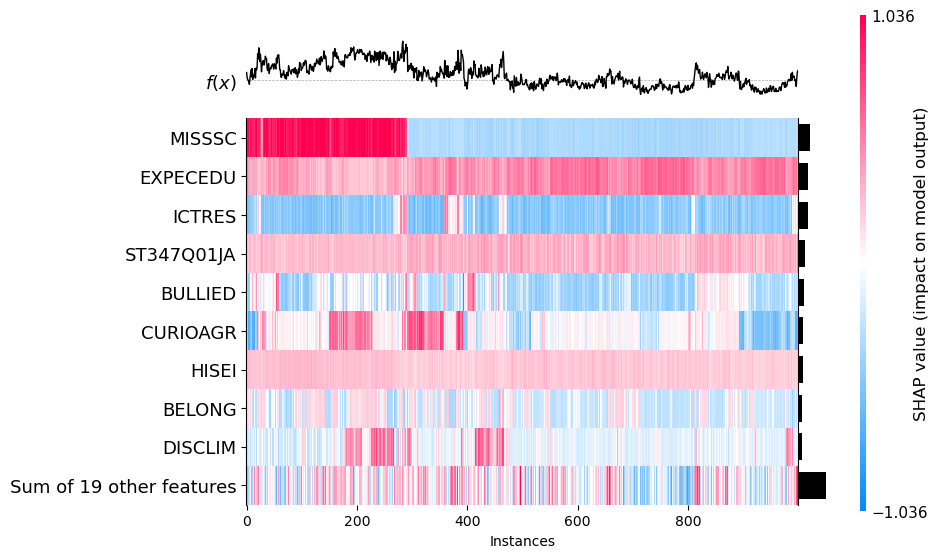

<Axes: xlabel='Instances'>

In [129]:
shap.plots.waterfall(shap_values_bin_means)

shap.plots.bar(shap_values_bin,max_display=10)
shap.summary_plot(shap_values_bin, X_test, plot_type="bar", max_display=10)

shap.plots.heatmap(shap_values_bin[:1000])

0.58075225
0.41924775
AUC:0.850


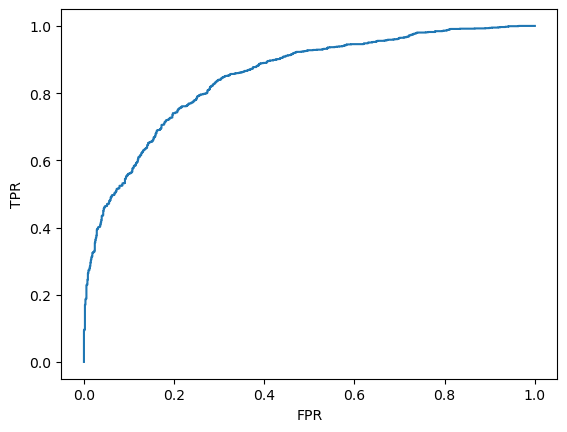

In [115]:
#ROC-AUC xgboost

from sklearn.metrics import roc_auc_score, roc_curve

y_proba_xgboost = best_model_xgb.predict_proba(X_test)[:, 1]
rf_auc=roc_auc_score(y_test,y_proba_xgboost)
fpr, tpr, thresholds = roc_curve(y_test, y_proba_xgboost)
plt.plot(fpr,tpr)
plt.xlabel("FPR")
plt.ylabel("TPR")

print(best_model_xgb.predict_proba(X_test)[:,1].mean())
print(best_model_xgb.predict_proba(X_test)[:,0].mean())
print("AUC:{:.3f}".format(rf_auc))

plt.savefig('ROC-AUC_XGB.jpg') 

In [117]:
#SVM
#from sklearn.svm import SVC
from sklearn.preprocessing import MinMaxScaler
#from sklearn.metrics import accuracy_score
#from sklearn.metrics import classification_report

#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

# Scale the features using MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# Create an SVM classifier with an RBF kernel
#svm_model = SVC(kernel='rbf', C=1, gamma='scale')  # C is the regularization parameter, gamma controls the influence of a single training point

# Train the SVM classifier
#svm_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
#y_pred = svm_model.predict(X_test_scaled)

# Evaluate the model
#print("Accuracy:", accuracy_score(y_test, y_pred))
#print("Classification Report:\n", classification_report(y_test, y_pred))

In [121]:
#Randomized SVM
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

svm_model = SVC(probability=True,kernel='rbf')

# Define the hyperparameters to search
param_dist = {
    'C': uniform(0.1, 10),  # Regularization parameter C, sampled uniformly between 0.1 and 10
    'gamma': uniform(0.01, 1),  # Kernel coefficient gamma, sampled uniformly between 0.01 and 1
    'degree': randint(2, 6),  # Degree of the polynomial kernel function (not used with RBF kernel but useful for other kernels)
    'kernel': ['rbf']  # We are using the RBF kernel
}

# Set up RandomizedSearchCV
random_search_SVM = RandomizedSearchCV(svm_model, param_distributions=param_dist, n_iter=100, random_state=42, cv=3, verbose=1)

# Train the model using RandomizedSearchCV
random_search_SVM.fit(X_train_scaled, y_train)

# Get the best hyperparameters from the search
print("Best hyperparameters:", random_search_SVM.best_params_)

# Make predictions on the test set using the best model
y_pred_SVM = random_search_SVM.best_estimator_.predict(X_test_scaled)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred_SVM))
print("Classification Report:\n", classification_report(y_test, y_pred_SVM))

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best hyperparameters: {'C': 4.2103701331823125, 'degree': 4, 'gamma': 0.28864646423661144, 'kernel': 'rbf'}
Accuracy: 0.5713615023474179
Classification Report:
               precision    recall  f1-score   support

         0.0       0.00      0.00      0.00       913
         1.0       0.57      1.00      0.73      1217

    accuracy                           0.57      2130
   macro avg       0.29      0.50      0.36      2130
weighted avg       0.33      0.57      0.42      2130



D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Confusion Matrix:
 [[693 245]
 [211 997]]


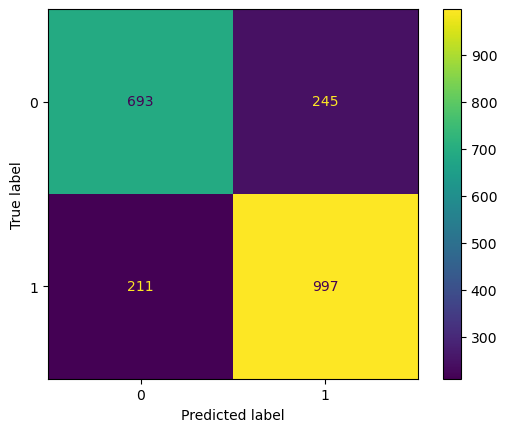

In [336]:
#Confusion Matrix SVM
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_SVM)
print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.viridis)
plt.show()

AUC:0.874


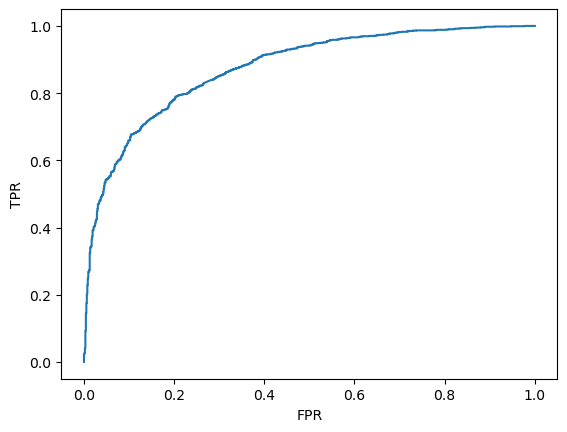

In [43]:
#ROC-AUC SVM

from sklearn.metrics import roc_auc_score,roc_curve

best_model_SVM=random_search_SVM.best_estimator_
y_proba_SVM = best_model_SVM.predict_proba(X_test_scaled)[:, 1]
rf_auc=roc_auc_score(y_test,y_proba_SVM)
fpr, tpr, thresholds = roc_curve(y_test, y_proba_SVM)
plt.plot(fpr,tpr)
plt.xlabel("FPR")
plt.ylabel("TPR")

print("AUC:{:.3f}".format(rf_auc))

In [142]:
#Decision Tree

# Import necessary libraries
#import pandas as pd
#import numpy as np
#from sklearn.model_selection import train_test_split
#from sklearn.tree import DecisionTreeClassifier, plot_tree
#from sklearn.metrics import accuracy_score
#import matplotlib.pyplot as plt

# Split the dataset into 80% training and 20% testing
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)
#X_train=X_train_resampled
#y_train=y_train_resampled

# 3. Train a Decision Tree Classifier
#clf = DecisionTreeClassifier(random_state=20)
#clf.fit(X_train, y_train)

# 4. Predict on the test data
#y_pred_DT = clf.predict(X_test)

# 5. Evaluate the model performance
#accuracy = accuracy_score(y_test, y_pred_DT)
#print(f"Accuracy of Decision Tree Classifier: {accuracy:.4f}")



Accuracy of Decision Tree Classifier: 0.6775


In [123]:
# RandomizedSearchCV Decision Tree
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from scipy.stats import randint
import matplotlib.pyplot as plt

#X_train=X_train_resampled
#y_train=y_train_resampled
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Define the hyperparameter search space for Decision Tree
param_dist = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': randint(2, 20),  # Randomly choose between 2 and 20
    'min_samples_leaf': randint(1, 20),   # Randomly choose between 1 and 20
    'criterion': ['gini', 'entropy'],     # Use either Gini or Entropy as the splitting criterion
    'max_features': ['auto', 'sqrt', 'log2', None],
    'splitter': ['best', 'random']        # Use best or random strategy for splitting nodes
}

# 4. Initialize the Decision Tree classifier
clf_dt = DecisionTreeClassifier(random_state=42)

# 5. Use RandomizedSearchCV to search for the best hyperparameters
random_search = RandomizedSearchCV(
    clf_dt, 
    param_distributions=param_dist,
    n_iter=100,               # Number of random combinations to try
    cv=5,                     # 5-fold cross-validation
    random_state=42,          # For reproducibility
    n_jobs=-1,                # Use all available CPUs
    verbose=1                 # Display progress
)

# 6. Fit the RandomizedSearchCV object to the training data
random_search.fit(X_train, y_train)

# 7. Get the best model from the random search
best_model_dt = random_search.best_estimator_

# 8. Make predictions using the best model
y_pred_dt = best_model_dt.predict(X_test)

# 9. Evaluate the performance
accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Accuracy of the best Decision Tree model: {accuracy:.4f}")

# 10. Display the best hyperparameters found by RandomizedSearchCV
print("Best hyperparameters found: ", random_search.best_params_)


Fitting 5 folds for each of 100 candidates, totalling 500 fits
Accuracy of the best Decision Tree model: 0.6653
Best hyperparameters found:  {'criterion': 'gini', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 16, 'min_samples_split': 2, 'splitter': 'best'}


D:\anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
115 fits failed out of a total of 500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
91 fits failed with the following error:
Traceback (most recent call last):
  File "D:\anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "D:\anaconda\Lib\site-packages\sklearn\base.py", line 1466, in wrapper
    estimator._validate_params()
  File "D:\anaconda\Lib\site-packages\sklearn\base.py", line 666, in _validate_params
    validate_parameter_constraints(
  File "D:\anaconda\Lib\site-packages\sklearn\utils\_param_validation.py", line 95, in validate_param

In [125]:
#Classification Report xgboost
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred_dt,target_names=["0","1"],digits=3))

              precision    recall  f1-score   support

           0      0.591     0.711     0.645       913
           1      0.744     0.631     0.683      1217

    accuracy                          0.665      2130
   macro avg      0.668     0.671     0.664      2130
weighted avg      0.679     0.665     0.667      2130

